# Python code for issue #2:

**Description:** Map offshore wind farms around the globe

**Created on:** November 23, 2026

**Created by:** Sabrina Chow

# 0) Set-Up

## 0.A) Import packages

In [1]:
import pandas as pd
import folium
from folium.plugins import MarkerCluster
import branca.colormap as cm
import matplotlib.pyplot as plt

## 0.B) Define constants

In [2]:
GIT_PATH = "/Users/sabrinachow/Documents/University of Chicago/Harris Social Impact Fellowship/ItoLab/windfish/"
BOX_PATH = "/Users/sabrinachow/Library/CloudStorage/Box-Box/wind_farms_and_fish/"

# 1) Data Cleaning

## 1.A) Load in data

The primary dataset we use for this analysis is the [Global Wind Power Tracker](https://globalenergymonitor.org/projects/global-wind-power-tracker#whats-inside) by Global Energy Monitor. This data comes from a variety of sources, including government data, new reports, and reports by power companies. GEM's website says the data is validated, but they only provide a partial list of [data sources](https://docs.google.com/spreadsheets/d/1V-fJ1U6j-Z8TkQ_rJ5a34xXs_rgZxUj_bsKVp858zF8/edit?gid=0#gid=0). 

In [3]:
path = GIT_PATH + "raw_data/Global-Wind-Power-Tracker-February-2026.xlsx"   # downloaded file
df = pd.read_excel(path, sheet_name="Data")
print(df.columns.tolist())

['Date Last Researched', 'Country/Area', 'Project Name', 'Phase Name', 'Project Name in Local Language / Script', 'Other Name(s)', 'Capacity (MW)', 'Installation Type', 'Status', 'Start year', 'Retired year', 'Operator', 'Operator Name in Local Language / Script', 'Owner', 'Owner Name in Local Language / Script', 'Hydrogen', 'Associated Storage', 'Latitude', 'Longitude', 'Location accuracy', 'City', 'Local area (taluk, county)', 'Major area (prefecture, district)', 'State/Province', 'Subregion', 'Region', 'GEM location ID', 'GEM phase ID', 'Other IDs (location)', 'Other IDs (unit/phase)', 'Wiki URL']


## 1.B) Clean data

In [4]:
# Rename columns
cols = {
    "Project Name": "name",
    "GEM location ID": "loc_id",
    "Capacity (MW)": "mw",
    "Status": "status",
    "Start year": "start_year",
    "Installation Type": "install_type",
    "Country/Area": "country",
    "Latitude": "lat",
    "Longitude": "lon",
}
df = df.rename(columns=cols)[list(cols.values())]
n_start = len(df)

# Convert relevant cols to numeric
df["mw"] = pd.to_numeric(df["mw"], errors="coerce")
df["start_year"] = pd.to_numeric(df["start_year"], errors="coerce")

# Color by start-year bin
def year_color(y):
    if pd.isna(y):  return "gray"
    if y < 2010:    return "#2c7bb6"
    if y < 2015:    return "#abd9e9"
    if y < 2020:    return "#fdae61"
    return "#d7191c"

In [5]:
# Filter to offshore wind farms only
df = df[df["install_type"].str.contains("offshore", case=False, na=False)]
n_offshore = len(df)
print(f"Dropped by offshore filter: {n_start - n_offshore:,} ({n_start:,} -> {n_offshore:,})")

# Drop rows with missing coordinates
df = df.dropna(subset=["lat", "lon"])
n_coords = len(df)
print(f"Dropped by non-NA coordinate filter: {n_offshore - n_coords:,} ({n_offshore:,} -> {n_coords:,})")

# Remove canceled projects
df = df[~df["status"].str.contains("cancelled")]
n_canceled = len(df)
print(f"Dropped by non-canceled filter: {n_coords - n_canceled:,} ({n_coords:,} -> {n_canceled:,})")

Dropped by offshore filter: 31,171 (33,248 -> 2,077)
Dropped by non-NA coordinate filter: 0 (2,077 -> 2,077)
Dropped by non-canceled filter: 375 (2,077 -> 1,702)


# 2) Build Map

In [6]:
m = folium.Map(location=[50, 5], zoom_start=4, tiles=None)
folium.TileLayer(
    tiles="https://server.arcgisonline.com/ArcGIS/rest/services/Ocean/World_Ocean_Base/MapServer/tile/{z}/{y}/{x}",
    attr="Tiles &copy; Esri, GEBCO, NOAA, National Geographic, and other contributors",
    name="Esri Ocean",
).add_to(m)
folium.TileLayer(
    tiles="https://server.arcgisonline.com/ArcGIS/rest/services/Canvas/World_Light_Gray_Base/MapServer/tile/{z}/{y}/{x}",
    attr="Tiles &copy; Esri, HERE, Garmin, and other contributors",
    name="Esri Light Gray",
    show=False,
).add_to(m)
cluster = MarkerCluster(name="Offshore wind farms").add_to(m)

for _, r in df.iterrows():
    color = year_color(r["start_year"])
    radius = 4 + (r["mw"] ** 0.5) / 3 if pd.notna(r["mw"]) else 4   # size ~ capacity
    popup = (
        f"<b>{r['name']}</b><br>"
        f"Country: {r['country']}<br>"
        f"Capacity: {r['mw']:,.0f} MW<br>"
        f"Status: {r['status']}<br>"
        f"Start year: {int(r['start_year']) if pd.notna(r['start_year']) else 'n/a'}"
    )
    folium.CircleMarker(
        location=[r["lat"], r["lon"]],
        radius=radius, color=color, fill=True, fill_color=color, fill_opacity=0.8,
        popup=folium.Popup(popup, max_width=250),
    ).add_to(cluster)

# Custom legend
legend_html = """
<div style="position: fixed; bottom: 30px; left: 30px; z-index: 9999;
            background: white; padding: 10px; border: 1px solid #999; font-size: 13px;">
<b>Start year</b><br>
<span style="color:#2c7bb6">●</span> before 2010<br>
<span style="color:#abd9e9">●</span> 2010-2014<br>
<span style="color:#fdae61">●</span> 2015-2019<br>
<span style="color:#d7191c">●</span> 2020+<br>
<span style="color:gray">●</span> unknown
</div>"""
m.get_root().html.add_child(folium.Element(legend_html))

folium.LayerControl().add_to(m)
m

In [7]:
# m.save(GIT_PATH + "figures/issue02_offshore_wind_map.html")
m.save(BOX_PATH + "figures/issue02_offshore_wind_map.html")

# 3) Plots of Wind Energy

## 3.A) Globally

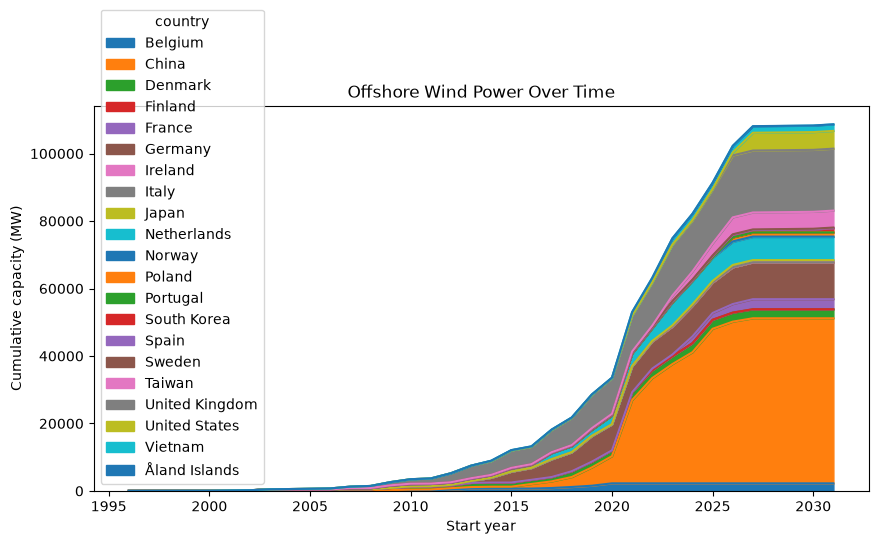

In [8]:
op = df[df["status"].str.lower().isin(["operating", "construction"])]
yearly = (op.groupby(["start_year", "country"])["mw"].sum()
            .unstack(fill_value=0).sort_index())

ax = yearly.cumsum().plot.area(figsize=(10, 5))
ax.set_ylabel("Cumulative capacity (MW)")
ax.set_xlabel("Start year")
ax.set_title("Offshore Wind Power Over Time")
plt.show()

## 3.B) By country

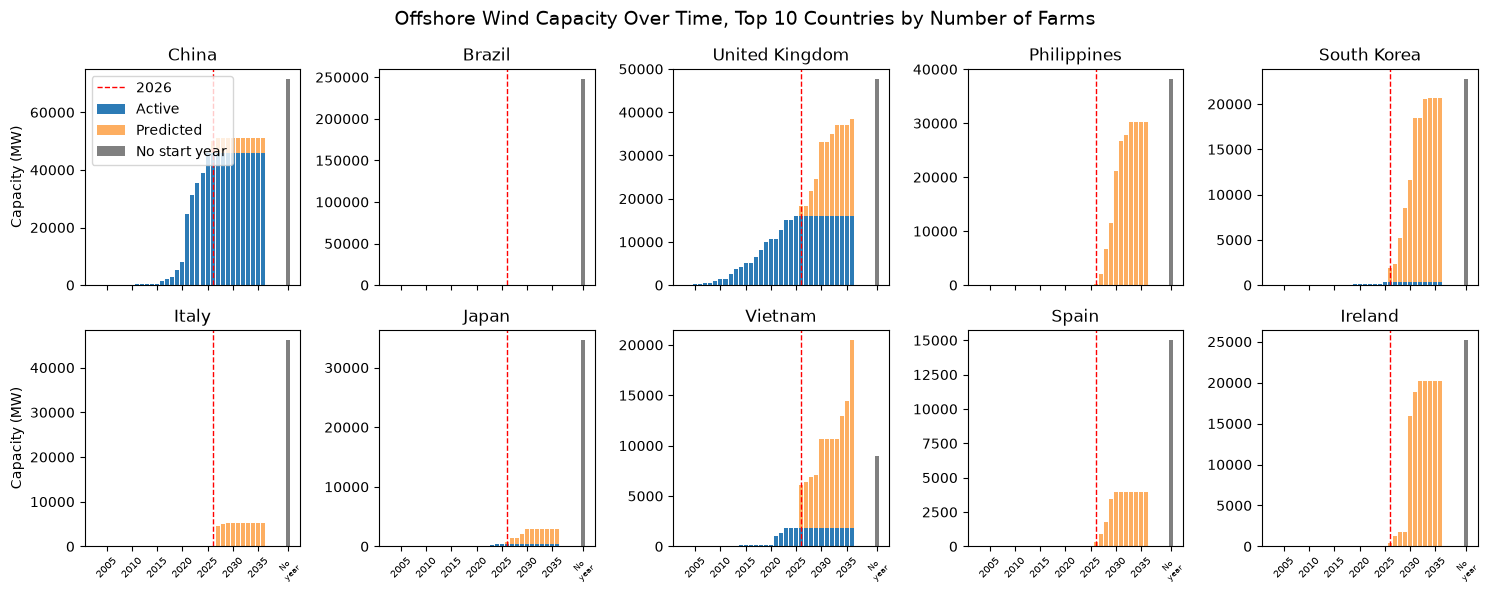

In [ ]:
# Group statuses: "active" = operating; "predicted" = not yet built
status_to_group = {
    "operating": "active",
    "construction": "predicted",
    "pre-construction": "predicted",
    "announced": "predicted",
}

plan_df = df.copy()
plan_df["group"] = plan_df["status"].str.lower().map(status_to_group)
plan_df = plan_df.dropna(subset=["group", "mw"])   # drops retired/mothballed/etc. and missing MW

# Top 10 countries by number of farms, among the statuses plotted
top10_plan = (plan_df.groupby("country")["loc_id"].nunique()
                     .sort_values(ascending=False).head(10).index)
plan_df = plan_df[plan_df["country"].isin(top10_plan)]

# Split into projects with and without a start year
dated_df = plan_df.dropna(subset=["start_year"]).copy()
dated_df["start_year"] = dated_df["start_year"].astype(int)
undated_df = plan_df[plan_df["start_year"].isna()]

year_range = range(dated_df["start_year"].min(), dated_df["start_year"].max() + 1)
undated_x = year_range.stop + 4                     # position of the side bar
tick_years = [y for y in year_range if y % 5 == 0]

color_active, color_predicted = "#2c7bb6", "#fdae61"
groups = ["active", "predicted"]

fig_plan, axes_plan = plt.subplots(2, 5, figsize=(15, 6), sharex=True)#, sharey=True)

for panel, country_name in zip(axes_plan.flat, top10_plan):
    # Cumulative MW by start year, split by group
    by_year = (dated_df[dated_df["country"] == country_name]
               .pivot_table(index="start_year", columns="group", values="mw", aggfunc="sum")
               .reindex(index=year_range, columns=groups)
               .fillna(0)
               .cumsum())

    panel.bar(by_year.index, by_year["active"], color=color_active, label="Active")
    panel.bar(by_year.index, by_year["predicted"], bottom=by_year["active"],
              color=color_predicted, label="Predicted")

    # Side bar: projects with no start year (not cumulative, just the total)
    no_year = (undated_df[undated_df["country"] == country_name]
               .groupby("group")["mw"].sum()
               .reindex(groups, fill_value=0))
    panel.bar(undated_x, no_year.sum(), color="gray", label="No start year")

    # Vertical line at 2026
    panel.axvline(2026, color="red", linestyle="--", linewidth=1, label="2026")

    panel.set_xticks(tick_years + [undated_x])
    panel.set_xticklabels([str(y) for y in tick_years] + ["No\nyear"])
    panel.tick_params(axis="x", rotation=45, labelsize=7)
    tick_labels = panel.get_xticklabels()
    if tick_labels:
        tick_labels[-1].set_fontsize(6)
    panel.set_title(country_name)

for panel in axes_plan[:, 0]:
    panel.set_ylabel("Capacity (MW)")
axes_plan[0, 0].legend(loc="upper left")

fig_plan.suptitle("Offshore Wind Capacity Over Time, Top 10 Countries by Number of Farms", fontsize=14)
plt.tight_layout()
# fig_plan.savefig(GIT_PATH + "figures/issue02_offshore_wind_by_country.png", dpi=300, bbox_inches="tight")
fig_plan.savefig(BOX_PATH + "figures/issue02_offshore_wind_by_country.png", dpi=300, bbox_inches="tight")
plt.show()

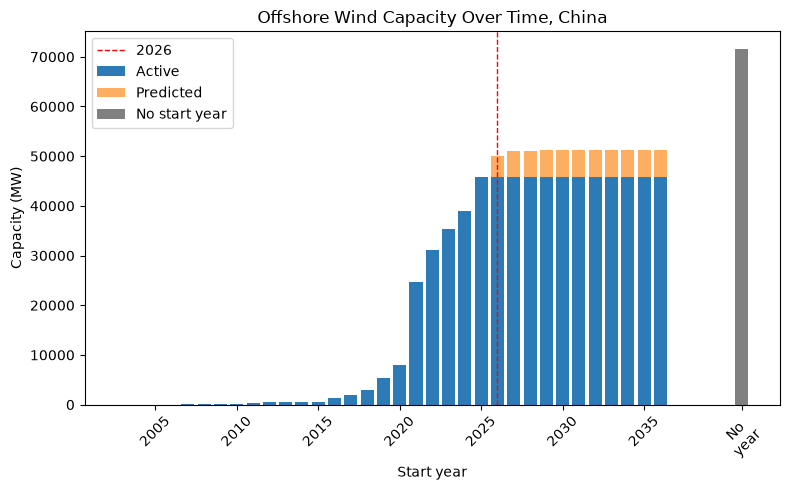

In [ ]:
# China only (uses dated_df, undated_df, year_range, etc. from the cell above)
china_by_year = (dated_df[dated_df["country"] == "China"]
                 .pivot_table(index="start_year", columns="group", values="mw", aggfunc="sum")
                 .reindex(index=year_range, columns=groups)
                 .fillna(0)
                 .cumsum())

china_no_year = (undated_df[undated_df["country"] == "China"]
                 .groupby("group")["mw"].sum()
                 .reindex(groups, fill_value=0))

fig_china, axis_china = plt.subplots(figsize=(8, 5))

axis_china.bar(china_by_year.index, china_by_year["active"], color=color_active, label="Active")
axis_china.bar(china_by_year.index, china_by_year["predicted"], bottom=china_by_year["active"],
               color=color_predicted, label="Predicted")
axis_china.bar(undated_x, china_no_year.sum(), color="gray", label="No start year")

# Vertical line at 2026
axis_china.axvline(2026, color="red", linestyle="--", linewidth=1, label="2026")

axis_china.set_xticks(tick_years + [undated_x])
axis_china.set_xticklabels([str(y) for y in tick_years] + ["No\nyear"])
axis_china.tick_params(axis="x", rotation=45)
axis_china.set_xlabel("Start year")
axis_china.set_ylabel("Capacity (MW)")
axis_china.set_title("Offshore Wind Capacity Over Time, China")
axis_china.legend(loc="upper left")

plt.tight_layout()
# fig_china.savefig(GIT_PATH + "figures/issue02_offshore_wind_china.png", dpi=300, bbox_inches="tight")
fig_china.savefig(BOX_PATH + "figures/issue02_offshore_wind_china.png", dpi=300, bbox_inches="tight")
plt.show()